In [1]:
print(__doc__)

import os
import itertools
import numpy as np
import matplotlib.pyplot as plt

from sklearn import svm, datasets
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, f1_score, precision_recall_fscore_support

Automatically created module for IPython interactive environment


In [2]:
labels = ["angry", "disgust", "fear", "happy", "sad", "surprise", "neutral"]
file_names = [
#     '/home/ubuntu/KDEF_ExpW.txt'
    "/home/ubuntu/Repos/face_classification/src/AffectNet_ExpW.txt",
    "/home/ubuntu/Repos/face_classification/src/AffectNet_KDEF.txt",
    "/home/ubuntu/Repos/face_classification/src/AffectNet_FER2013.txt",
    "/home/ubuntu/Repos/face_classification/src/FER2013_ExpW.txt",
    "/home/ubuntu/Repos/face_classification/src/FER2013_KDEF.txt",
    "/home/ubuntu/Repos/face_classification/src/FER2013_AffectNet.txt",
    "/home/ubuntu/Repos/face_classification/src/ExpW_FER2013.txt",
    "/home/ubuntu/Repos/face_classification/src/ExpW_AffectNet.txt",
    "/home/ubuntu/Repos/face_classification/src/KDEF_FER2013.txt",
    "/home/ubuntu/Repos/face_classification/src/KDEF_AffectNet.txt"
#     '/home/ubuntu/Repos/capstone_2/bravo/client/utils/natural_fer.txt',
#     '/home/ubuntu/Repos/capstone_2/bravo/client/utils/natural_affectnet.txt',
#     '/home/ubuntu/Repos/capstone_2/bravo/client/utils/natural_all.txt'
]

In [3]:
def plot_confusion_matrix(cm, classes,
                          normalize=False,
                          title='Confusion matrix',
                          cmap=plt.cm.Blues):
    """
    This function prints and plots the confusion matrix.
    Normalization can be applied by setting `normalize=True`.
    """
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
#         print("Normalized confusion matrix")
#     else:
#         print('Confusion matrix, without normalization')

#     print(cm)

    plt.imshow(cm, interpolation='nearest', cmap=cmap)
    plt.title(title)
    plt.colorbar()
    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes, rotation=45)
    plt.yticks(tick_marks, classes)

    fmt = '.0f' if normalize else 'd'
#     fmt = 'd'
    thresh = cm.max() / 2.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt),
                 horizontalalignment="center",
                 color="white" if cm[i, j] > thresh else "black")

    plt.ylabel('Actual sentiment')
    plt.xlabel('Predicted sentiment')
    plt.tight_layout()

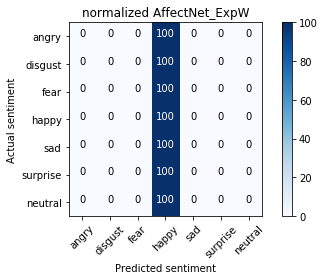

/home/ubuntu/miniconda3/envs/capstone_2/lib/python3.6/site-packages/sklearn/metrics/classification.py:1143: UndefinedMetricWarning: Precision and F-score are ill-defined and being set to 0.0 in labels with no predicted samples.
  'precision', 'predicted', average, warn_for)


============== MACRO ==============
Precision:  0.047524632286
Recall:     0.142857142857
F1 Score:   0.071322301503
============== MICRO ==============
Precision:  0.332672426002
Recall:     0.332672426002
F1 Score:   0.332672426002


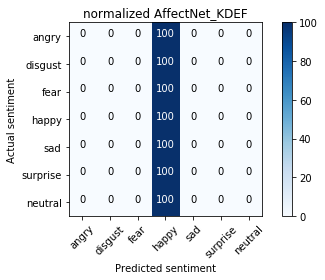

============== MACRO ==============
Precision:  0.0204164965292
Recall:     0.142857142857
F1 Score:   0.0357270453733
============== MICRO ==============
Precision:  0.142915475704
Recall:     0.142915475704
F1 Score:   0.142915475704


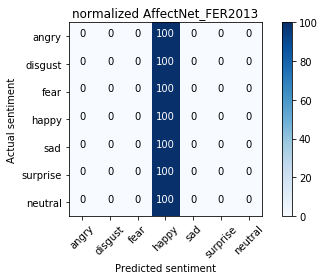

============== MACRO ==============
Precision:  0.0357829536362
Recall:     0.142857142857
F1 Score:   0.0572307182968
============== MICRO ==============
Precision:  0.250480675454
Recall:     0.250480675454
F1 Score:   0.250480675454


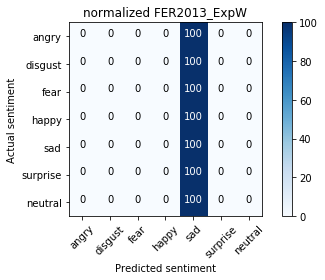

============== MACRO ==============
Precision:  0.0164329368408
Recall:     0.142857142857
F1 Score:   0.0294753120883
============== MICRO ==============
Precision:  0.115030557886
Recall:     0.115030557886
F1 Score:   0.115030557886


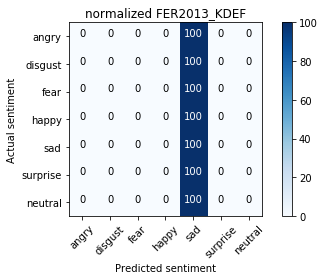

============== MACRO ==============
Precision:  0.0203873301056
Recall:     0.142857142857
F1 Score:   0.0356823808673
============== MICRO ==============
Precision:  0.142711310739
Recall:     0.142711310739
F1 Score:   0.142711310739


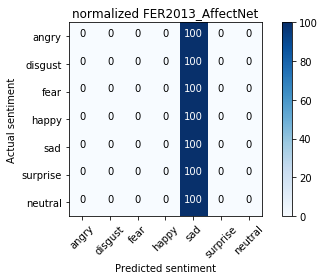

============== MACRO ==============
Precision:  0.0129033252196
Recall:     0.142857142857
F1 Score:   0.0236688063022
============== MICRO ==============
Precision:  0.090323276537
Recall:     0.090323276537
F1 Score:   0.090323276537


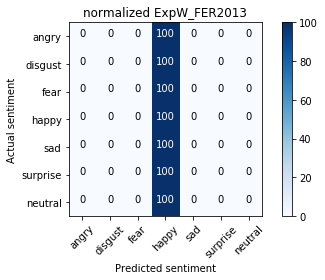

============== MACRO ==============
Precision:  0.0357829536362
Recall:     0.142857142857
F1 Score:   0.0572307182968
============== MICRO ==============
Precision:  0.250480675454
Recall:     0.250480675454
F1 Score:   0.250480675454


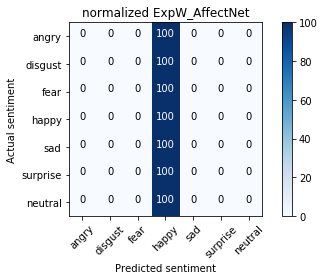

============== MACRO ==============
Precision:  0.0670616018336
Recall:     0.142857142857
F1 Score:   0.0912755918723
============== MICRO ==============
Precision:  0.469431212835
Recall:     0.469431212835
F1 Score:   0.469431212835


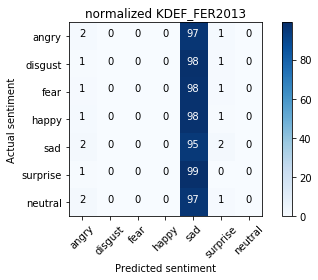

============== MACRO ==============
Precision:  0.0469011878223
Recall:     0.138841249534
F1 Score:   0.0448649048346
============== MICRO ==============
Precision:  0.163986959066
Recall:     0.163986959066
F1 Score:   0.163986959066


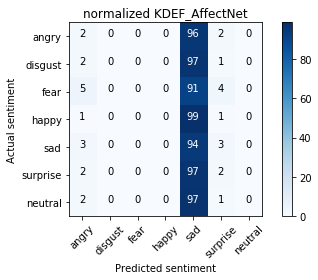

============== MACRO ==============
Precision:  0.040332152056
Recall:     0.140078476719
F1 Score:   0.031717761095
============== MICRO ==============
Precision:  0.0878772168503
Recall:     0.0878772168503
F1 Score:   0.0878772168503


In [4]:
for file_name in file_names:
    open_file = open(file_name)
    lines = open_file.read().splitlines()
    img_count = len(lines)
    y_pred = []
    y_actual = []

    for line in lines:
        temp = line.split(",")
        y_pred.append(float(temp[0]))
        y_actual.append(float(temp[1]))
    open_file.close()
    
    title = file_name.split("/")[-1][:-4]
    
    # Compute confusion matrix
    cnf_matrix = confusion_matrix(y_actual, y_pred)
    np.set_printoptions(precision=2)

    # Plot non-normalized confusion matrix
#     plt.figure()
#     plot_confusion_matrix(cnf_matrix, classes=labels,
#                           title=title)

    # # Plot normalized confusion matrix
    plt.figure()
    # plot_confusion_matrix(cnf_matrix, classes=class_names, normalize=True,
    #                       title='Normalized confusion matrix')
    plot_confusion_matrix(cnf_matrix, classes=labels, normalize=True, title="normalized "+title)

    output_title = title + ".png"
    plt.savefig(output_title)
    plt.show()
    
    
    y_actual = np.array(y_actual)
    y_pred = np.array(y_pred)

#     micro_score = f1_score(y_actual, y_pred, average = "micro")
#     macro_score = f1_score(y_actual, y_pred, average = "macro")

#     # print(y_actual)
#     # print(y_pred)
#     print(micro_score)
#     print(macro_score)
    
    p_mac, r_mac, f_mac, s_mac = precision_recall_fscore_support(y_actual, y_pred, average = "macro")
    print("============== MACRO ==============")
    print("Precision: ", str(p_mac))
    print("Recall:    ", str(r_mac))
    print("F1 Score:  ", str(f_mac))
#     print("S: ", str(s))

    p_mic, r_mic, f_mic, s_mic = precision_recall_fscore_support(y_actual, y_pred, average = "micro")
    print("============== MICRO ==============")
    print("Precision: ", str(p_mic))
    print("Recall:    ", str(r_mic))
    print("F1 Score:  ", str(f_mic))
#     print("S: ", str(s))
    
    del(y_pred)
    del(y_actual)
    del(cnf_matrix)

In [ ]:
duh = ['a', 'b']

for i, b in enumerate(duh):
    print(i)